In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shivanshranjan4213/edda-transformer-cnn-fusion-attention/hybrid_xattn_query_val_probs.npy
/kaggle/input/datasets/shivanshranjan4213/edda-transformer-cnn-fusion-attention/hybrid_xattn_query_test_probs.npy
/kaggle/input/datasets/shivanshranjan4213/edda-transformer-cnn-fusion-attention/hybrid_xattn_query_test_labels.npy
/kaggle/input/datasets/shivanshranjan4213/edda-transformer-cnn-fusion-attention/hybrid_xattn_query_thresholds.npy


In [2]:
import os
D = "/kaggle/input/datasets/shivanshranjan4213/edda-transformer-cnn-fusion-attention"     # <-- your copied path
print(os.listdir(D))

['hybrid_xattn_query_val_probs.npy', 'hybrid_xattn_query_test_probs.npy', 'hybrid_xattn_query_test_labels.npy', 'hybrid_xattn_query_thresholds.npy']


Macro-F1: 0.7828 | expected 0.7769
    Class  Support Threshold  Precision  Recall     F1  AUROC  AUPRC
   Normal      595      0.49     0.7213  0.9395 0.8161 0.8925 0.8745
       DR      399      0.43     0.6419  0.7995 0.7121 0.8953 0.8335
 Glaucoma      143      0.35     0.6441  0.7972 0.7125 0.9550 0.7861
      AMD       85      0.35     0.8219  0.7059 0.7595 0.9547 0.8198
   Myopia       71      0.17     0.8625  0.9718 0.9139 0.9990 0.9850
Macro avg     1293               0.7383  0.8428 0.7828 0.9393 0.8598


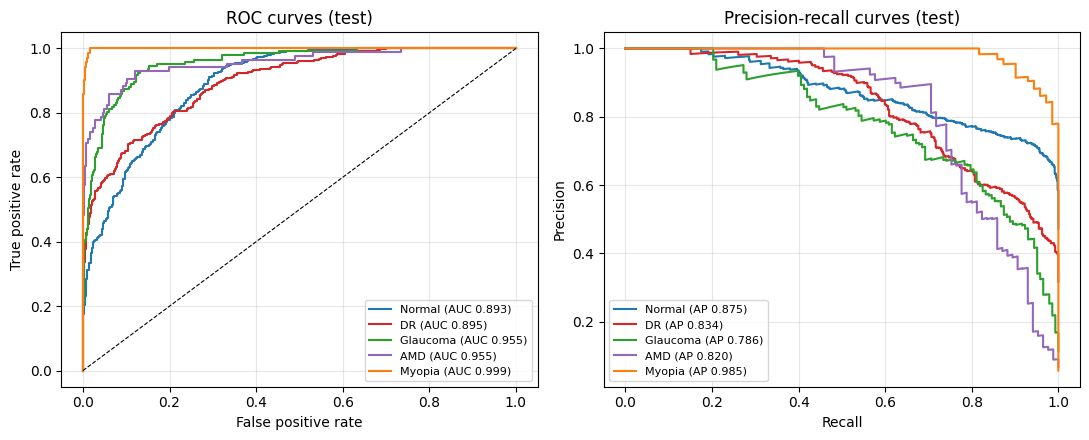

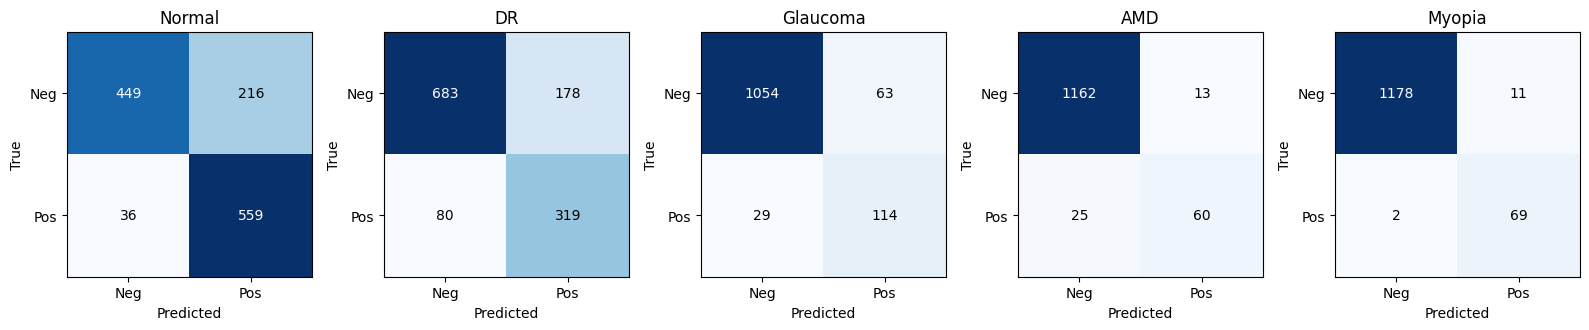

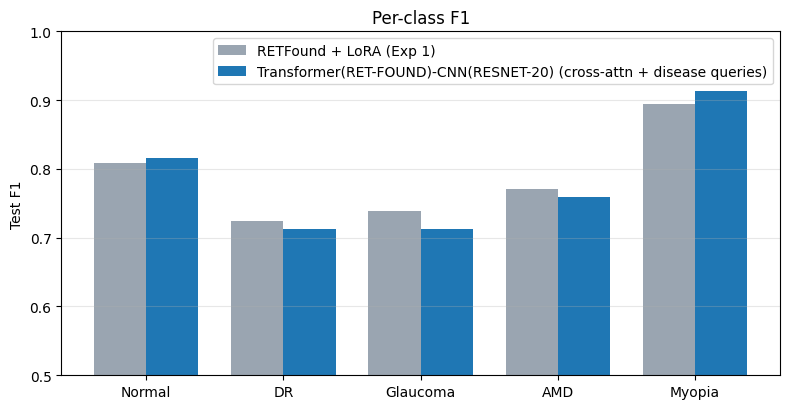

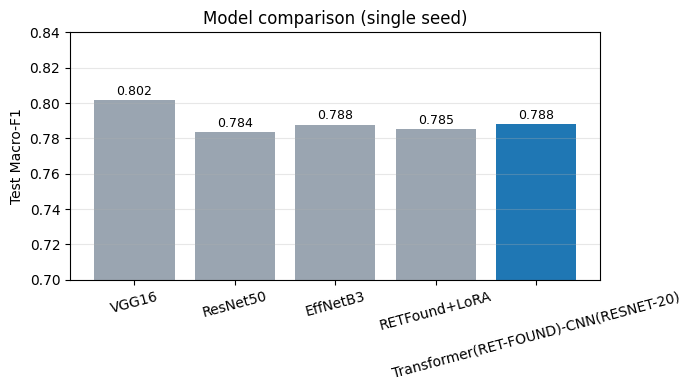

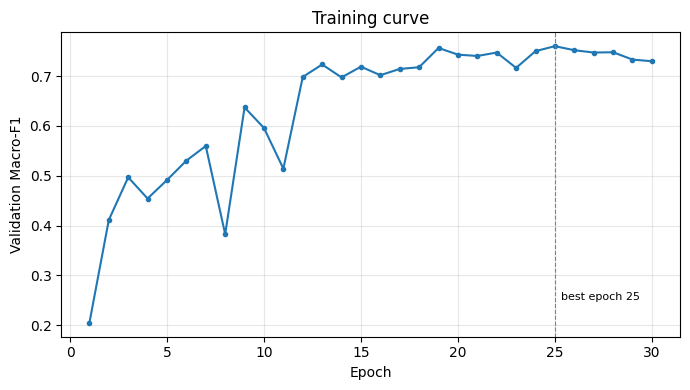

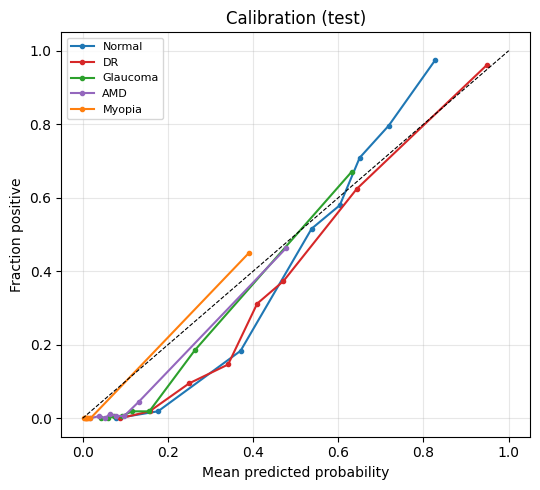

In [3]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.calibration import calibration_curve

D = "/kaggle/input/datasets/shivanshranjan4213/edda-transformer-cnn-fusion-attention"     # <-- your copied path
TAG = "hybrid_xattn_query"
L = ["Normal", "DR", "Glaucoma", "AMD", "Myopia"]
Pt = np.load(f"{D}/{TAG}_test_probs.npy"); Yt = np.load(f"{D}/{TAG}_test_labels.npy").astype(int)
th = np.load(f"{D}/{TAG}_thresholds.npy"); pred = (Pt >= th).astype(int)

# 1) SANITY CHECK: must print 0.7769 (the number from the log)
f1s = [f1_score(Yt[:, c], pred[:, c]) for c in range(5)]
print("Macro-F1:", round(np.mean(f1s), 4), "| expected 0.7769")

# 2) Per-class metrics table
rows = []
for c, n in enumerate(L):
    rows.append(dict(Class=n, Support=int(Yt[:, c].sum()), Threshold=round(float(th[c]), 2),
                     Precision=precision_score(Yt[:, c], pred[:, c]), Recall=recall_score(Yt[:, c], pred[:, c]),
                     F1=f1s[c], AUROC=roc_auc_score(Yt[:, c], Pt[:, c]), AUPRC=average_precision_score(Yt[:, c], Pt[:, c])))
tab = pd.DataFrame(rows).round(4)
tab.loc[len(tab)] = ["Macro avg", int(Yt.sum()), "", *tab[["Precision","Recall","F1","AUROC","AUPRC"]].mean().round(4)]
print(tab.to_string(index=False)); tab.to_csv("per_class_metrics.csv", index=False)

C = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e"]

# 3) ROC + PR curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for c, n in enumerate(L):
    fpr, tpr, _ = roc_curve(Yt[:, c], Pt[:, c]); ax[0].plot(fpr, tpr, color=C[c], label=f"{n} (AUC {roc_auc_score(Yt[:, c], Pt[:, c]):.3f})")
    p, r, _ = precision_recall_curve(Yt[:, c], Pt[:, c]); ax[1].plot(r, p, color=C[c], label=f"{n} (AP {average_precision_score(Yt[:, c], Pt[:, c]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(title="ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate")
ax[1].set(title="Precision-recall curves (test)", xlabel="Recall", ylabel="Precision")
for a in ax: a.legend(loc="lower right" if a is ax[0] else "lower left", fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("fig_roc_pr.png", dpi=300); plt.show()

# 4) Confusion matrix per class (one-vs-rest, at tuned thresholds)
fig, ax = plt.subplots(1, 5, figsize=(16, 3.4))
for c, n in enumerate(L):
    cm = confusion_matrix(Yt[:, c], pred[:, c]); ax[c].imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax[c].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    ax[c].set(title=n, xticks=[0, 1], yticks=[0, 1], xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"], xlabel="Predicted", ylabel="True")
plt.tight_layout(); plt.savefig("fig_confusion.png", dpi=300); plt.show()

# 5) Per-class F1 vs RETFound-only (Exp 1)
exp1 = [0.8093, 0.7249, 0.7386, 0.7702, 0.8939]
x = np.arange(5); w = .38
plt.figure(figsize=(8, 4.2))
plt.bar(x - w/2, exp1, w, label="RETFound + LoRA (Exp 1)", color="#9aa5b1"); plt.bar(x + w/2, f1s, w, label="Transformer(RET-FOUND)-CNN(RESNET-20) (cross-attn + disease queries)", color="#1f77b4")
plt.xticks(x, L); plt.ylabel("Test F1"); plt.ylim(0.5, 1); plt.title("Per-class F1"); plt.legend(); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("fig_perclass_f1.png", dpi=300); plt.show()

# 6) Macro-F1 comparison, all models so far
names = ["VGG16", "ResNet50", "EffNetB3", "RETFound+LoRA", "Transformer(RET-FOUND)-CNN(RESNET-20)"]; vals = [0.8018, 0.7836, 0.7877, 0.7854, 0.7879]
plt.figure(figsize=(7, 4)); b = plt.bar(names, vals, color=["#9aa5b1"]*4 + ["#1f77b4"])
for r_, v in zip(b, vals): plt.text(r_.get_x() + r_.get_width()/2, v + .003, f"{v:.3f}", ha="center", fontsize=9)
plt.ylim(0.7, 0.84); plt.ylabel("Test Macro-F1"); plt.title("Model comparison (single seed)"); plt.xticks(rotation=15); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("fig_model_comparison.png", dpi=300); plt.show()

# 7) Training curve (validation Macro-F1 per epoch, from your log)
val = [0.2045,0.4110,0.4968,0.4542,0.4913,0.5303,0.5596,0.3826,0.6371,0.5959,0.5141,0.6983,0.7233,0.6974,0.7189,
       0.7018,0.7144,0.7178,0.7565,0.7431,0.7404,0.7473,0.7165,0.7501,0.7601,0.7520,0.7473,0.7479,0.7332,0.7298]
plt.figure(figsize=(7, 4)); plt.plot(range(1, 31), val, marker="o", ms=3); plt.axvline(25, ls="--", c="gray", lw=.8)
plt.text(25.3, 0.25, "best epoch 25", fontsize=8); plt.xlabel("Epoch"); plt.ylabel("Validation Macro-F1"); plt.title("Training curve"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("fig_training_curve.png", dpi=300); plt.show()

# 8) Calibration (reliability) curves
plt.figure(figsize=(5.5, 5))
for c, n in enumerate(L):
    fp, mp = calibration_curve(Yt[:, c], Pt[:, c], n_bins=8, strategy="quantile"); plt.plot(mp, fp, marker="o", ms=3, color=C[c], label=n)
plt.plot([0, 1], [0, 1], "k--", lw=.8); plt.xlabel("Mean predicted probability"); plt.ylabel("Fraction positive"); plt.title("Calibration (test)"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("fig_calibration.png", dpi=300); plt.show()